# 01 Data understanding
**Goal:** check the raw 10-minute data (date format, gaps, duplicates, units, outliers) and create the hourly dataset used by every later notebook.

**Input:** `data/raw/Tetuan_City_power_consumption.csv`  **Output:** `data/processed/hourly.csv`

In [1]:
import pandas as pd
import numpy as np

PATH = "../data/raw/Tetuan_City_power_consumption.csv"
df = pd.read_csv(PATH)
df.columns = df.columns.str.strip().str.replace(r"\s+", " ", regex=True)
print(df.columns.tolist())

['DateTime', 'Temperature', 'Humidity', 'Wind Speed', 'general diffuse flows', 'diffuse flows', 'Zone 1 Power Consumption', 'Zone 2 Power Consumption', 'Zone 3 Power Consumption']


In [2]:
parts = df["DateTime"].str.split(" ").str[0].str.split("/", expand=True).astype(int)
print("max of first part :", parts[0].max())
print("max of second part :", parts[1].max())

max of first part : 12
max of second part : 31


In [3]:
# Month comes first (the first part reaches 12, the second reaches 31)
FMT = "%m/%d/%Y %H:%M"

df["DateTime"] = pd.to_datetime(df["DateTime"], format=FMT)
df = df.set_index("DateTime").sort_index()
print(df.index.min(), "->", df.index.max())
print("unique days:", df.index.normalize().nunique())

2017-01-01 00:00:00 -> 2017-12-30 23:50:00


unique days: 364


In [4]:
full = pd.date_range(df.index.min(), df.index.max(), freq="10min")
missing = full.difference(df.index)
print("expected rows:", len(full), "| actual:", len(df))
print("missing timestamps:", len(missing))
print("duplicate timestamps:", df.index.duplicated().sum())
print("step sizes:\n", df.index.to_series().diff().value_counts().head())

expected rows: 52416 | actual: 52416
missing timestamps: 0
duplicate timestamps: 0
step sizes:
 DateTime
0 days 00:10:00    52415
Name: count, dtype: int64


In [5]:
zones = [c for c in df.columns if "Power" in c]
print(df[zones].describe().T)
print((df[zones] <= 0).sum())

                            count          mean          std           min  \
Zone 1 Power Consumption  52416.0  32344.970564  7130.562564  13895.696200   
Zone 2 Power Consumption  52416.0  21042.509082  5201.465892   8560.081466   
Zone 3 Power Consumption  52416.0  17835.406218  6622.165099   5935.174070   

                                   25%           50%           75%  \
Zone 1 Power Consumption  26310.668692  32265.920340  37309.018185   
Zone 2 Power Consumption  16980.766032  20823.168405  24713.717520   
Zone 3 Power Consumption  13129.326630  16415.117470  21624.100420   

                                  max  
Zone 1 Power Consumption  52204.39512  
Zone 2 Power Consumption  37408.86076  
Zone 3 Power Consumption  47598.32636  
Zone 1 Power Consumption    0
Zone 2 Power Consumption    0
Zone 3 Power Consumption    0
dtype: int64


<Axes: title={'center': 'Daily mean total load'}, xlabel='DateTime'>

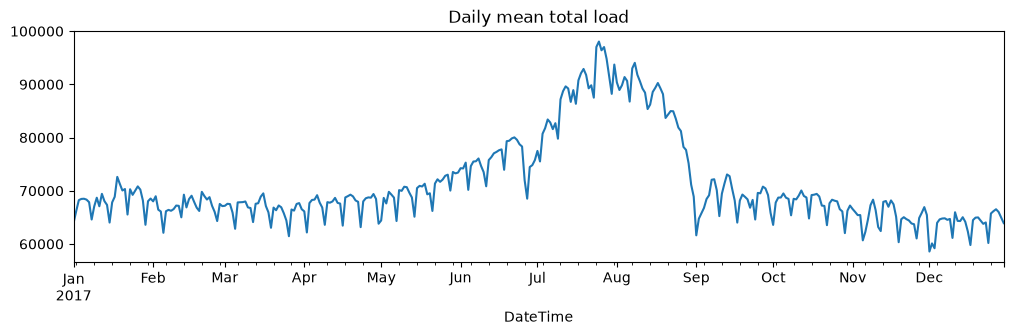

In [6]:
df[zones].sum(axis=1).resample("D").mean().plot(figsize=(12, 3), title="Daily mean total load")

In [7]:
for z in zones:
    q1, q3 = df[z].quantile([.25, .75]); iqr = q3 - q1
    n = ((df[z] < q1 - 1.5*iqr) | (df[z] > q3 + 1.5*iqr)).sum()
    print(z, "IQR outliers:", n)

print(df["Zone 3 Power Consumption"].nlargest(5))
print(df[["Temperature", "Humidity", "Wind Speed"]].describe().T)

Zone 1 Power Consumption IQR outliers: 0
Zone 2 Power Consumption IQR outliers: 7
Zone 3 Power Consumption IQR outliers: 1191
DateTime
2017-07-24 20:10:00    47598.32636
2017-07-27 20:10:00    47598.32636
2017-07-26 20:00:00    47580.25105
2017-07-26 20:10:00    47507.94979
2017-07-26 20:20:00    47441.67364
Name: Zone 3 Power Consumption, dtype: float64
               count       mean        std     min     25%     50%     75%  \
Temperature  52416.0  18.810024   5.815476   3.247  14.410  18.780  22.890   
Humidity     52416.0  68.259518  15.551177  11.340  58.310  69.860  81.400   
Wind Speed   52416.0   1.959489   2.348862   0.050   0.078   0.086   4.915   

                max  
Temperature  40.010  
Humidity     94.800  
Wind Speed    6.483  


In [8]:
# When and at what hour do the Zone 3 IQR outliers occur?
z = df["Zone 3 Power Consumption"]
q1, q3 = z.quantile([.25, .75]); iqr = q3 - q1
out = z[(z < q1 - 1.5 * iqr) | (z > q3 + 1.5 * iqr)]
print("outliers:", len(out), "| below the lower fence:", int((z < q1 - 1.5 * iqr).sum()))
print("share by month (%):\n", (out.groupby(out.index.month).size() / len(out) * 100).round(1).to_string())
print("share between 18:00 and 22:59 (%):", round(out.index.hour.isin(range(18, 23)).mean() * 100, 1))

outliers: 1191 | below the lower fence: 0
share by month (%):
 DateTime
7    63.8
8    36.2
share between 18:00 and 22:59 (%): 89.3


In [9]:
hourly = df.resample("h").mean()
hourly["total"] = hourly[zones].sum(axis=1)
print(df["Temperature"].resample("h").count().value_counts())  # readings per hour
print(hourly.shape)
hourly.to_csv("../data/processed/hourly.csv")

Temperature
6    8736
Name: count, dtype: int64
(8736, 9)


## Conclusion
- 52,416 rows at 10-minute spacing, 2017-01-01 to 2017-12-30 (364 days = 52 weeks). Dec 31 is missing, so there is no New Year's Eve.
- Date format is month/day (the first part reaches 12, the second reaches 31). No missing or duplicate timestamps, all steps are exactly 10 minutes.
- Column names had double spaces (`Zone 2  Power Consumption`), cleaned in the first cell. Units are undocumented, so values are treated as relative power units.
- Zone 3 has 1,191 IQR outliers (see the check cell above). All are high values, all in July (64%) and August (36%), and 89% between 6 and 11 PM, which fits real summer-evening peaks, so they are kept. Not confirmed: the exact value 47598.33 appears on two different days and was not investigated.
- **Decision:** resample to hourly (6 readings per hour, no partial hours, 8,736 rows) and forecast the **total** of the three zones. Per-zone forecasts are future work.